# Bank Marketing

**Data Science Challenge** · Author: Solano Jacon

A Portuguese bank sells term deposits by phone. Every call takes an agent's time, and most clients say no. This notebook builds a model that ranks clients by their chance of subscribing **before they are called**, so the calls can go to the most promising clients first. [Challenge description](README.md).

**Summary**

- **45,211 calls** from May 2008 to November 2010; **11.7% of the clients subscribed**. The file has no year, but the rows are in date order, so the full date of each call could be rebuilt.
- **The campaign changed in mid-2009.** Until June 2009 the bank called about 3,100 clients a month and 7.5% subscribed. From July 2009 it called about 300 a month, mostly clients from earlier campaigns, and about half subscribed. The calendar columns (month and day) mostly mark these two periods, not a real seasonal effect.
- **The model is validated the way it would be used:** chosen on the second half of 2009 and tested on 2010, after training only on earlier calls. `duration`, which is only known when the call ends, is left out.
- A logistic regression ranks the 2010 clients with a **ROC AUC of 0.69**. A random train/test split would have reported **0.80**, mostly by mixing the two periods.
- Calling the **top 30% of clients by score reaches 44% of the subscribers**, and 75% of the clients called subscribe, against 52% when calling at random.
- **A success in the previous campaign is by far the strongest signal.** Mobile phones help; repeated calls and housing or personal loans lower the chances.

**Contents**

1. Data reading and preparation
2. Exploratory analysis
3. Feature preparation
4. Train/validation/test split
5. Model choice
6. Model training, saving and scoring
7. Test results
8. What drives subscription
9. Using the model in production
10. Actionable insights and next steps

## Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import ParameterGrid, train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             precision_score, recall_score, f1_score, confusion_matrix)
from sklearn.inspection import permutation_importance

DATA_PATH = '../../portfolio-data/Bank_Marketing/data/bank-full.csv'
MODEL_PATH = '../../portfolio-data/Bank_Marketing/models/subscription_model.joblib'
VALIDATION_START = '2009-07-01'   # train: May 2008-Jun 2009 / validation: Jul-Dec 2009, to choose the model
TEST_START = '2010-01-01'         # final model: May 2008-Dec 2009 / test: Jan-Nov 2010
RANDOM_STATE = 42

import warnings   # month values unseen in training are expected when testing the calendar features (section 5.2)
warnings.filterwarnings('ignore', message='Found unknown categories')

In [2]:
# Chart style
BLUE, ORANGE, GRAY = '#2a78d6', '#eb6834', '#8a8985'
INK, INK_2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'xtick.color': INK_2, 'ytick.color': INK_2, 'font.size': 10, 'legend.frameon': False,
    'lines.linewidth': 2,
})
pct = lambda x, d=1: f'{x:.{d}%}'
percent_axis = plt.FuncFormatter(lambda v, _: f'{v:.0%}')
round_ticks = lambda: plt.MaxNLocator(6, steps=[1, 2, 5, 10])

## 1. Data reading and preparation

### 1.1 Reading

The data is the public [Bank Marketing dataset](https://archive.ics.uci.edu/dataset/222/bank+marketing) (Moro et al., 2011), also distributed on [Kaggle](https://www.kaggle.com/datasets/abdelazizsami/bank-marketing). It comes as two semicolon-separated files:

- `bank-full.csv`: all 45,211 calls, ordered by date.
- `bank.csv`: a random 10% sample of the same calls, meant for testing slow algorithms. It adds no information, so it is not used.

In [3]:
raw = pd.read_csv(DATA_PATH, sep=';')
print(f'{len(raw):,} rows x {raw.shape[1]} columns')
raw.head(3)

45,211 rows x 17 columns


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no


### 1.2 Rebuilding the call dates

Each row describes the **last call** made to one client during a campaign. The documentation says the rows are ordered by date, from May 2008 to November 2010, but there is no year column: only the month and day of that last call.

The year can be rebuilt. Walking down the rows, the (month, day) pair should only move forward, except when a new year starts.

In [4]:
# Shared with the production pipeline: src/bank_marketing/data.py
from bank_marketing.data import MONTHS, prepare_calls

calls = prepare_calls(raw)   # adds the full date and the 0/1 target `subscribed`
year_starts = calls.index[calls['date'].dt.year.diff() > 0]
print(f'Rows where the calendar goes backwards: {len(year_starts)}, at rows {list(year_starts)}')

print(f'Period: {calls["date"].min():%d %b %Y} to {calls["date"].max():%d %b %Y}')
print(f'Calls on a weekday (Mon-Fri): {pct(calls["date"].dt.dayofweek.lt(5).mean())}')
print(f'Share of clients who subscribed: {pct(calls["subscribed"].mean())}')

Rows where the calendar goes backwards: 2, at rows [27729, 42591]
Period: 05 May 2008 to 17 Nov 2010
Calls on a weekday (Mon-Fri): 99.9%
Share of clients who subscribed: 11.7%


The calendar goes backwards exactly twice, at the turns of 2008–2009 and 2009–2010, so every call gets its full date. Two checks support the result:

- The period matches the documentation: May 2008 to November 2010.
- 99.9% of the rebuilt dates fall on a weekday, as expected from a call center. A wrong year would move the calls to other days of the week, weekends included.

### 1.3 Data dictionary

| Column | Description | Known before the call? |
|---|---|---|
| `age`, `job`, `marital`, `education` | Client profile (`marital = divorced` includes widowed) | Yes |
| `default`, `balance`, `housing`, `loan` | Credit in default, average yearly balance (euros), housing loan, personal loan | Yes |
| `contact` | Type of phone used: `cellular`, `telephone` or `unknown` | Yes |
| `month`, `day` | Month and day of the last call (the year is rebuilt above as `date`) | Yes, but see section 2.3 |
| `duration` | Duration of the last call, in seconds | **No**: only known when the call ends |
| `campaign` | Calls made to this client in this campaign, including the last one | Yes |
| `pdays` | Days since the client was last called in a previous campaign (`-1`: never) | Yes |
| `previous` | Calls made to this client before this campaign | Yes |
| `poutcome` | Outcome of the previous campaign | Yes |
| `y` | **Target:** the client subscribed to a term deposit | — |

### 1.4 Missing values

In [5]:
print(f'Empty cells (NaN): {raw.isna().sum().sum()}')

unknown = (raw.select_dtypes(exclude='number') == 'unknown').sum()
unknown = unknown[unknown > 0].to_frame('unknown values')
unknown['share'] = (unknown['unknown values'] / len(raw)).map(pct)
unknown

Empty cells (NaN): 0


,unknown values,share
job,288,0.6%
education,1857,4.1%
contact,13020,28.8%
poutcome,36959,81.7%


In [6]:
never_called = raw['pdays'] == -1
print(f"pdays = -1 (never called before): {never_called.sum():,}")
print(f"previous = 0 (no calls before):    {(raw['previous'] == 0).sum():,}")
print(f"Both at once:                      {(never_called & (raw['previous'] == 0)).sum():,}")
print(f"poutcome = 'unknown':              {(raw['poutcome'] == 'unknown').sum():,}")

pdays = -1 (never called before): 36,954
previous = 0 (no calls before):    36,954
Both at once:                      36,954
poutcome = 'unknown':              36,959


- There are **no empty cells**, but four columns use `unknown` as a value.
- `pdays = -1` and `previous = 0` mark exactly the same 36,954 clients: those never called in an earlier campaign. For them, `poutcome` is `unknown` by definition; only 5 clients called before have an unknown outcome.

**Approach:** nothing is imputed or dropped.

- `unknown` is kept as a category of its own. It is not missing at random: for `poutcome` it means *never called before*, and section 2.3 shows that `contact = unknown` comes almost entirely from the first two months of data. Imputing a value would hide that information.
- `pdays = -1` cannot be used as a number, because it would sit next to "called yesterday". In section 3 it becomes the category `never` of a *days since the previous campaign* feature.

## 2. Exploratory analysis

### 2.1 Basic statistics and data types

In [7]:
raw.dtypes.value_counts().rename('columns').to_frame()

,columns
str,10
int64,7


In [8]:
raw.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.9,10.6,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.3,3044.8,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.8,8.3,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.2,257.5,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.8,3.1,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.2,100.1,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.6,2.3,0.0,0.0,0.0,0.0,275.0


In [9]:
raw.describe(exclude='number').T

,count,unique,top,freq
job,45211,12,blue-collar,9732
marital,45211,3,married,27214
education,45211,4,secondary,23202
default,45211,2,no,44396
housing,45211,2,yes,25130
loan,45211,2,no,37967
contact,45211,3,cellular,29285
month,45211,12,may,13766
poutcome,45211,4,unknown,36959
y,45211,2,no,39922


### 2.2 Distributions

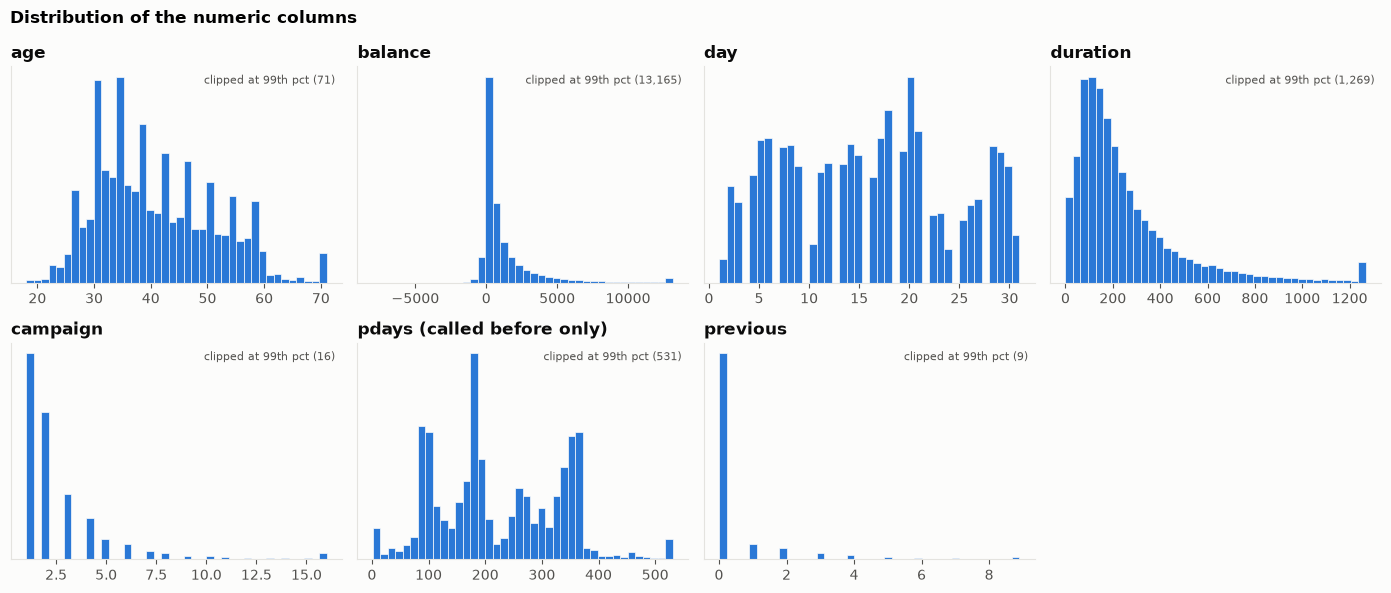

In [10]:
NUMERIC_RAW = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, column in zip(axes.flat, NUMERIC_RAW):
    values = raw[column]
    if column == 'pdays':
        values = values[values >= 0]   # -1 means never called before
    cap = values.quantile(0.99)
    ax.hist(values.clip(upper=cap), bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
    ax.set_title(column + (' (called before only)' if column == 'pdays' else ''))
    ax.set_yticks([])
    ax.grid(False)
    if values.max() > cap:
        ax.text(0.98, 0.92, f'clipped at 99th pct ({cap:,.0f})', transform=ax.transAxes,
                ha='right', fontsize=8, color=INK_2)
axes.flat[-1].axis('off')
fig.suptitle('Distribution of the numeric columns', x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
plt.show()

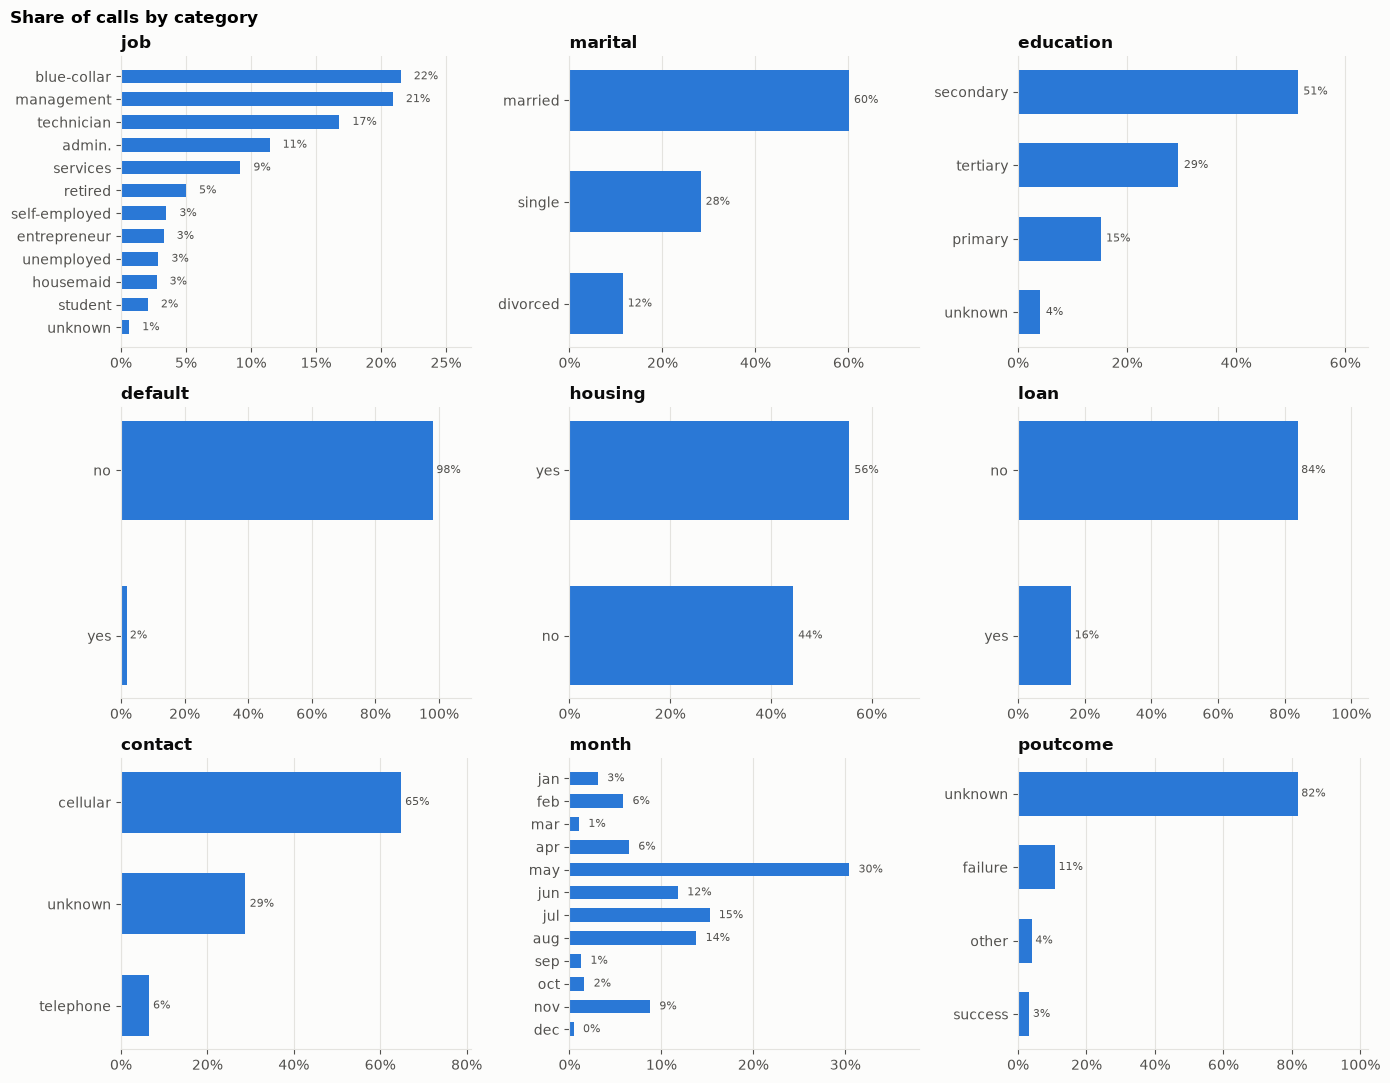

In [11]:
CATEGORICAL_RAW = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
fig, axes = plt.subplots(3, 3, figsize=(14, 11))
for ax, column in zip(axes.flat, CATEGORICAL_RAW):
    shares = raw[column].value_counts(normalize=True)
    if column == 'month':
        shares = shares.reindex(MONTHS)
    shares = shares.iloc[::-1]
    ax.barh(shares.index, shares.values, color=BLUE, height=0.6)
    for y_pos, value in enumerate(shares.values):
        ax.text(value + 0.01, y_pos, pct(value, 0), va='center', fontsize=8, color=INK_2)
    ax.set_title(column)
    ax.set_xlim(0, min(shares.max() * 1.25, 1.1))
    ax.xaxis.set_major_locator(round_ticks())
    ax.xaxis.set_major_formatter(percent_axis)
    ax.grid(axis='y', visible=False)
fig.suptitle('Share of calls by category', x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
plt.show()

- `balance`, `duration`, `campaign` and `previous` have long right tails: a few clients have very large balances or were called dozens of times. Section 3 caps or log-transforms them before modeling.
- `pdays` clusters around 90, 180 and 360 days after the previous campaign, which suggests campaigns at regular intervals.
- 30% of the calls happened in May, and most of the rest in the summer months. Section 2.3 shows that this is a matter of period, not of season.
- `default = yes` is rare (2%), and 82% of the clients were never called in an earlier campaign (`poutcome = unknown`).

### 2.3 The campaign changed over time

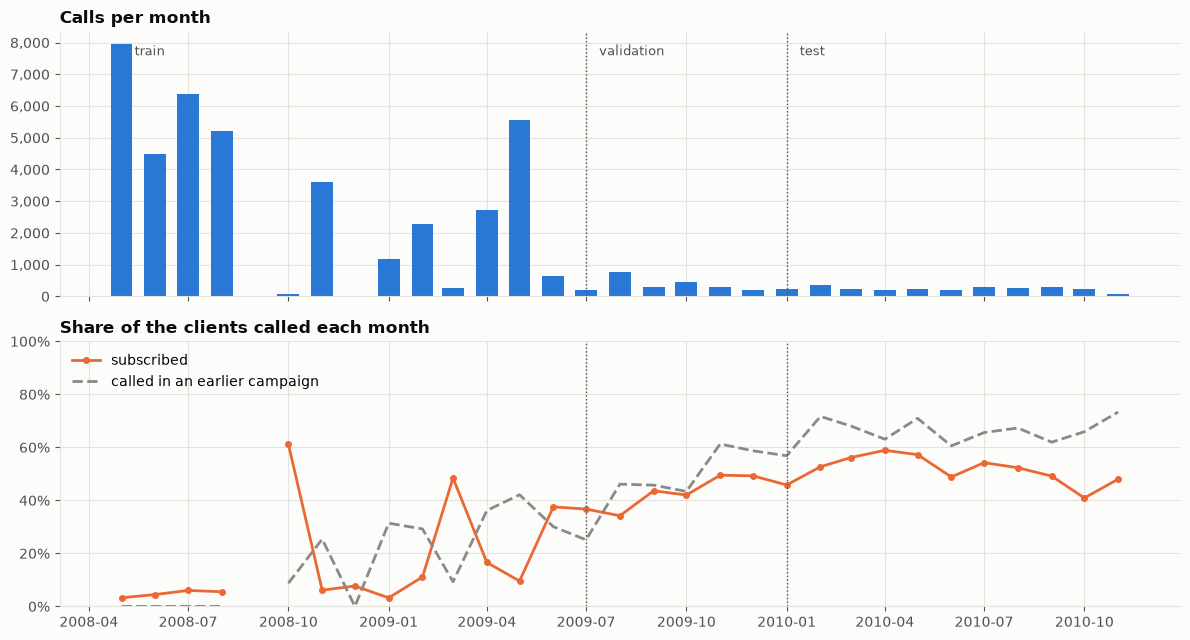

In [12]:
monthly = calls.groupby(calls['date'].dt.to_period('M')).agg(
    calls=('subscribed', 'size'), subscription_rate=('subscribed', 'mean'),
    called_before=('previous', lambda s: (s > 0).mean()))
monthly = monthly.reindex(pd.period_range(monthly.index.min(), monthly.index.max(), freq='M'))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
x = monthly.index.to_timestamp()
ax1.bar(x, monthly['calls'], width=20, color=BLUE)
ax1.set_title('Calls per month')
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax2.plot(x, monthly['subscription_rate'], color=ORANGE, marker='o', markersize=4, label='subscribed')
ax2.plot(x, monthly['called_before'], color=GRAY, linestyle='--', label='called in an earlier campaign')
ax2.set_title('Share of the clients called each month')
ax2.yaxis.set_major_formatter(percent_axis)
ax2.set_ylim(0, 1)
ax2.legend(loc='upper left')
for ax in (ax1, ax2):
    ax.axvline(pd.Timestamp(VALIDATION_START), color=INK_2, linewidth=1, linestyle=':')
    ax.axvline(pd.Timestamp(TEST_START), color=INK_2, linewidth=1, linestyle=':')
for label, start in [('train', '2008-05-01'), ('validation', VALIDATION_START), ('test', TEST_START)]:
    ax1.text(pd.Timestamp(start) + pd.Timedelta(days=12), 7600, label, color=INK_2, fontsize=9)
plt.tight_layout()
plt.show()

In [13]:
PHASES = {'May 2008 - Jun 2009': ('2008-01-01', VALIDATION_START),
          'Jul 2009 - Dec 2009': (VALIDATION_START, TEST_START),
          'Jan 2010 - Nov 2010': (TEST_START, '2011-01-01')}

def phase_summary(column):
    rows = {}
    for name, (start, end) in PHASES.items():
        part = calls[(calls['date'] >= start) & (calls['date'] < end)]
        rows[name] = part.groupby(column)['subscribed'].mean()
    return pd.DataFrame(rows)

phases = pd.DataFrame({name: {
    'calls': len(part),
    'calls per month': len(part) / part['date'].dt.to_period('M').nunique(),
    'subscribed': part['subscribed'].mean(),
    'called in an earlier campaign': (part['previous'] > 0).mean(),
    "previous outcome 'success'": (part['poutcome'] == 'success').mean(),
    "contact 'unknown'": (part['contact'] == 'unknown').mean(),
} for name, (start, end) in PHASES.items()
  for part in [calls[(calls['date'] >= start) & (calls['date'] < end)]]})
phases.style.format(lambda v: f'{v:,.0f}' if v > 1 else pct(v))

,May 2008 - Jun 2009,Jul 2009 - Dec 2009,Jan 2010 - Nov 2010
calls,"40,394","2,197","2,620"
calls per month,"3,107",366,238
subscribed,7.5%,40.6%,51.6%
called in an earlier campaign,13.6%,46.7%,65.7%
previous outcome 'success',0.9%,17.7%,28.7%
contact 'unknown',31.6%,0.2%,9.6%


The vertical lines mark the train, validation and test periods used from section 4 on. The data covers two very different ways of running the campaign:

- **Until June 2009, mass calling.** About 3,100 calls a month, mostly to clients never called before, and only 7.5% subscribed.
- **From July 2009, selective calling.** About 240 to 370 calls a month, a tenth of the earlier volume. Half to two thirds of these clients had been called in an earlier campaign, and 41% to 52% subscribed.

The data does not say why: it may be a change in strategy, in budget, or in demand for deposits after the 2008 crisis. The consequences for modeling are clear, though:

- The selective period holds **11% of the calls but 42% of the subscribers**. A random train/test split mixes the two periods, so a model can learn *which period a call belongs to* and look better than it would be on future calls.
- **The calendar marks the period.** 98% of the May calls are from the mass period, while 83% of the calls made in March, September, October and December are from the selective one. That is why those four months convert at 47% and May at 7%: the month says when the call was made, not that March is a good month to sell deposits. With less than three years of data, a real seasonal effect cannot be separated from the change in period.
- `contact = unknown` comes almost entirely from May and June 2008, when the phone type was not recorded.

### 2.4 Who subscribes

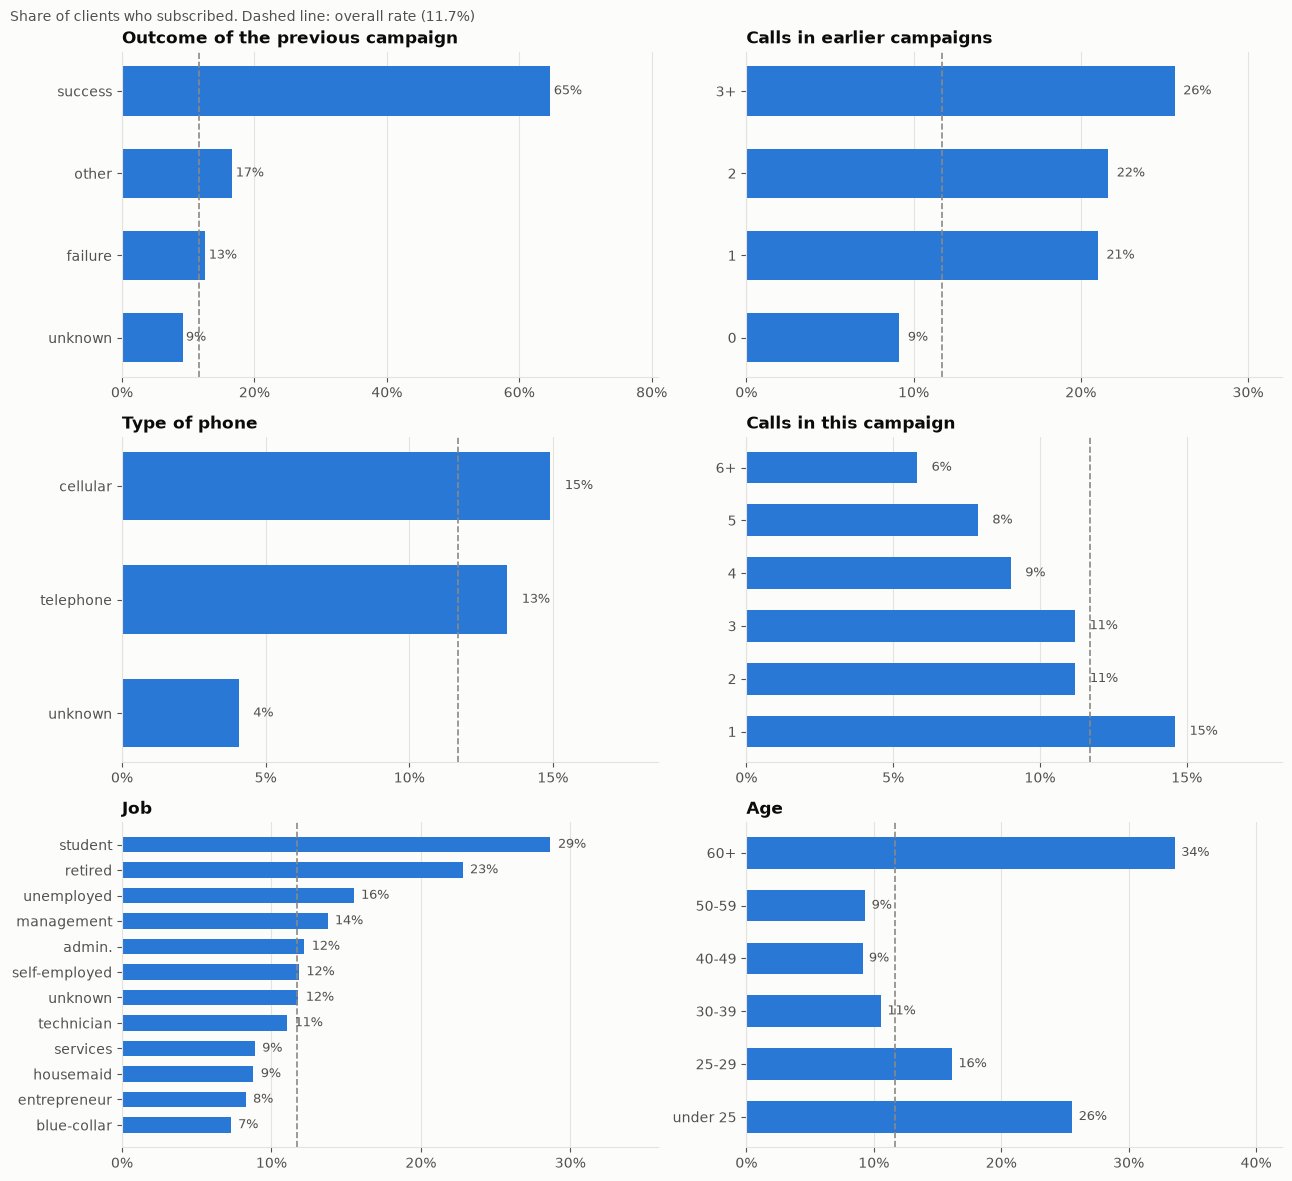

In [14]:
OVERALL_RATE = calls['subscribed'].mean()

def bar_panel(ax, stats, title):
    ax.barh([str(i) for i in stats.index], stats['mean'], color=BLUE, height=0.6)
    ax.axvline(OVERALL_RATE, color=GRAY, linestyle='--', linewidth=1.2)
    for y_pos, value in enumerate(stats['mean']):
        ax.text(value + 0.005, y_pos, pct(value, 0), va='center', fontsize=9, color=INK_2)
    ax.set_title(title)
    ax.grid(axis='y', visible=False)
    ax.xaxis.set_major_locator(round_ticks())
    ax.xaxis.set_major_formatter(percent_axis)
    ax.set_xlim(0, stats['mean'].max() * 1.25)

def rate_by(values, order=None):
    stats = calls.groupby(values)['subscribed'].agg(['mean', 'size'])
    return stats.reindex(order) if order else stats.sort_values('mean')

age_band = pd.cut(calls['age'], [0, 25, 30, 40, 50, 60, 200], right=False,
                  labels=['under 25', '25-29', '30-39', '40-49', '50-59', '60+'])
calls_band = calls['campaign'].clip(upper=6).map(lambda n: '6+' if n == 6 else str(n))
previous_band = calls['previous'].clip(upper=3).map(lambda n: '3+' if n == 3 else str(n))

fig, axes = plt.subplots(3, 2, figsize=(13, 12))
bar_panel(axes[0, 0], rate_by(calls['poutcome']), 'Outcome of the previous campaign')
bar_panel(axes[0, 1], rate_by(previous_band, ['0', '1', '2', '3+']), 'Calls in earlier campaigns')
bar_panel(axes[1, 0], rate_by(calls['contact']), 'Type of phone')
bar_panel(axes[1, 1], rate_by(calls_band, ['1', '2', '3', '4', '5', '6+']), 'Calls in this campaign')
bar_panel(axes[2, 0], rate_by(calls['job']), 'Job')
bar_panel(axes[2, 1], rate_by(age_band.astype(str), list(age_band.cat.categories)), 'Age')
fig.suptitle(f'Share of clients who subscribed. Dashed line: overall rate ({pct(OVERALL_RATE)})',
             x=0.01, ha='left', color=INK_2, fontsize=10)
plt.tight_layout()
plt.show()

- **A success in the previous campaign is the strongest signal.** 65% of those clients subscribe again, against 9% of the clients never called before.
- **Mobile phones convert better** than landlines (15% against 13%). Calls with an unknown phone type convert at 4%.
- **More calls, fewer subscriptions.** 15% of the clients called once subscribe, against 6% of those called six times or more in the same campaign.
- **Students, retired clients, and the youngest and oldest clients** subscribe the most. Blue-collar workers and entrepreneurs subscribe the least.

The rates above mix the phases of section 2.3. The table below repeats the strongest ones within each phase:

In [15]:
within = pd.concat({
    'previous outcome': phase_summary('poutcome'),
    'type of phone': phase_summary('contact'),
    'housing loan': phase_summary('housing'),
})
within.style.format(pct, na_rep='-')

- **A previous success, a mobile phone and the absence of a housing loan raise the rate in every period.** These effects are not artifacts of the change in mid-2009.
- **Having been called before is not enough.** Clients whose previous campaign failed subscribe *less* often than clients never called before (6.4% against 7.3% until June 2009, 34.5% against 45.7% in 2010). The higher rate of previously contacted clients in the chart above comes from the change in period and from the previous successes.
- The `unknown` phone type in the second half of 2009 covers only a handful of calls.

**`duration` is the strongest predictor, but it leaks the answer.**

In [16]:
calls.groupby('y')['duration'].describe()[['count', '25%', '50%', '75%']].round(0)

,count,25%,50%,75%
y,,,,
no,39922.0,95.0,164.0,279.0
yes,5289.0,244.0,426.0,725.0


Calls that ended in a subscription lasted a median of 426 seconds, against 164 for the others. But the duration is only known **after** the call: a long call is partly a consequence of the client's interest, and it cannot be used to decide whom to call. It is excluded from the features.

## 3. Feature preparation

**Selection principle:** use only what the bank knows **before the call**, when it decides whom to call.

| Group | Features | Preparation |
|---|---|---|
| Profile | `age`, `job`, `marital`, `education` | Categories one-hot encoded; `age` used as a number |
| Finances | `default`, `housing`, `loan`, `balance` | `yes`/`no` columns become a single 0/1 column; `balance` log-transformed, keeping its sign |
| Phone | `contact` | One-hot encoded, `unknown` included |
| This campaign | `calls_this_campaign` (from `campaign`) | Capped at 10 |
| Earlier campaigns | `previous_calls` (`previous`), `days_since_previous` (`pdays`), `previous_outcome` (`poutcome`) | `previous` capped at 10; `pdays` grouped into bands, with `never` for clients not called before |

**Excluded:**

- `duration`, known only when the call ends (section 2.4).
- `month` and `day`, which mostly identify the period of the call (section 2.3). Section 5.2 tests them anyway.

**Encoding and scaling:**

- Categories have no natural order (`unknown` is not *more* or *less* than `primary`), so they are one-hot encoded.
- For the logistic regression, numbers are standardized to mean 0 and standard deviation 1. Its regularization penalizes all coefficients alike, so the features must be on the same scale. Min-max scaling was not used because a single extreme value would squeeze all the others together.
- The long tails are tamed first: `balance` goes from −8,019 to 102,127 euros, and some clients were called 63 times.
- Tree models ignore scale and use the numbers as they are.

All encoding and scaling live **inside the model pipeline**, so they are learned from the training data only and travel with the saved model.

In [17]:
# Shared with the production pipeline: src/bank_marketing/features.py
from bank_marketing.features import CATEGORICAL, NUMERIC, build_features

CALENDAR_CATEGORICAL, CALENDAR_NUMERIC = ['month'], ['day']   # tested in section 5, not used in the final model

X = build_features(calls)
y = calls['subscribed']
FEATURES = CATEGORICAL + NUMERIC
print(f'{len(FEATURES)} features: {len(CATEGORICAL)} categorical, {len(NUMERIC)} numeric')
X[FEATURES].head(3)

13 features: 9 categorical, 4 numeric


,job,marital,education,default,housing,loan,contact,previous_outcome,days_since_previous,age,balance,calls_this_campaign,previous_calls
0,management,married,tertiary,no,yes,no,unknown,unknown,never,58,7.670429,1,0
1,technician,single,secondary,no,yes,no,unknown,unknown,never,44,3.401197,1,0
2,entrepreneur,married,secondary,no,yes,yes,unknown,unknown,never,33,1.098612,1,0


## 4. Train/validation/test split

The data is split **by time**, as the model would be used: trained on past calls and applied to the next ones.

- **Train** (May 2008 – June 2009): fits the candidate models.
- **Validation** (July – December 2009): chooses the model, its features and its parameters.
- **Test** (January – November 2010): used once, at the end, to measure the chosen model. The final model is refit on train and validation together.

The subscription rate rises from 7.5% in train to 52% in test. This is the hard case the model faces in practice: it has to rank clients in a period that looks different from the one it learned from.

In [18]:
is_train = calls['date'] < VALIDATION_START
is_validation = (calls['date'] >= VALIDATION_START) & (calls['date'] < TEST_START)
is_test = calls['date'] >= TEST_START

split = pd.DataFrame({name: {'period': f'{calls.loc[mask, "date"].min():%b %Y} - {calls.loc[mask, "date"].max():%b %Y}',
                             'calls': f'{mask.sum():,}', 'subscribed': pct(y[mask].mean())}
                      for name, mask in [('train', is_train), ('validation', is_validation), ('test', is_test)]}).T
split

,period,calls,subscribed
train,May 2008 - Jun 2009,"40,394",7.5%
validation,Jul 2009 - Dec 2009,"2,197",40.6%
test,Jan 2010 - Nov 2010,"2,620",51.6%


## 5. Model choice

### 5.1 Target and metric

The target is binary: the client **subscribed (1) or not (0)**.

The bank's decision is a ranking: *with the calls the team can make, whom should it call first?* The model is therefore judged by how well it **orders** clients:

- **ROC AUC** is the probability that a random subscriber is ranked above a random non-subscriber (0.5 is random, 1.0 is perfect). It does not depend on the subscription rate, which matters here because that rate goes from 7.5% to 52% across the periods. It is the main metric for choosing the model.
- **Average precision (PR AUC)** summarizes precision across all cutoffs and is more sensitive to the top of the ranking. It has to be read against the subscription rate of the period, which is what a random ranking scores.
- **Cumulative gains and lift** answer the business question directly: calling the top X% of clients reaches what share of the subscribers?

Accuracy is misleading: predicting that nobody subscribes is 88% accurate on the whole data. Precision, recall and F1 are reported for a concrete operating point in section 7.4.

### 5.2 Candidates

| Model | Why it is a candidate |
|---|---|
| **Random (dummy)** | The floor: calling clients in no particular order. |
| **Logistic regression** | A linear, interpretable baseline. Each coefficient says how a feature changes the odds of subscribing. |
| **Histogram gradient boosting** | Shallow decision trees built one after another, each correcting the previous ones. It captures non-linear effects and interactions, and it is usually the strongest choice for tabular data. |

Each model is trained on the train period and scored on the validation period, with and without the calendar features (`month` and `day`).

In [19]:
# Encoding, scaling and model in one pipeline, shared with the production pipeline: src/bank_marketing/model.py
from bank_marketing.model import make_pipeline

def validation_scores(pipeline, columns):
    pipeline.fit(X.loc[is_train, columns], y[is_train])
    scores = pipeline.predict_proba(X.loc[is_validation, columns])[:, 1]
    return {'ROC AUC': roc_auc_score(y[is_validation], scores),
            'Average precision': average_precision_score(y[is_validation], scores)}

MODELS = {
    'Random (dummy)': (lambda: DummyClassifier(strategy='stratified', random_state=RANDOM_STATE), False),
    'Logistic regression': (lambda: LogisticRegression(max_iter=2000), True),
    'Gradient boosting': (lambda: HistGradientBoostingClassifier(random_state=RANDOM_STATE), False),
}
comparison = {}
for name, (model, scale) in MODELS.items():
    comparison[(name, 'without month and day')] = validation_scores(make_pipeline(model(), scale=scale), FEATURES)
    comparison[(name, 'with month and day')] = validation_scores(
        make_pipeline(model(), CATEGORICAL + CALENDAR_CATEGORICAL, NUMERIC + CALENDAR_NUMERIC, scale),
        FEATURES + CALENDAR_CATEGORICAL + CALENDAR_NUMERIC)
comparison = pd.DataFrame(comparison).T
comparison.index.names = ['model', 'features']
comparison.round(3)

ROC AUC  Average precision
model               features                                         
Random (dummy)      without month and day    0.518              0.417
                    with month and day       0.518              0.417
Logistic regression without month and day    0.598              0.505
                    with month and day       0.581              0.480
Gradient boosting   without month and day    0.567              0.450
                    with month and day       0.561              0.450

- **The logistic regression ranks best:** ROC AUC of 0.60, against 0.57 for gradient boosting. The validation period is hard, because the models learn from the mass period and are judged on the selective one.
- **The calendar features make both models worse.** What the models learn about each month in 2008–2009 does not carry over to the following months; September, for example, never appears in the training period. This confirms the decision to leave them out.
- Gradient boosting's extra flexibility does not help: with a shift this large between periods, the simpler model generalizes better.

### 5.3 Hyperparameter tuning

In [20]:
GRIDS = {
    'Logistic regression': (lambda **p: LogisticRegression(max_iter=2000, **p), True,
                            {'C': [0.01, 0.1, 1, 10]}),
    'Gradient boosting': (lambda **p: HistGradientBoostingClassifier(random_state=RANDOM_STATE, **p), False,
                          {'learning_rate': [0.03, 0.1], 'max_leaf_nodes': [7, 31], 'min_samples_leaf': [20, 200],
                           'l2_regularization': [0, 10]}),
}
tuning = []
for name, (model, scale, grid) in GRIDS.items():
    for params in ParameterGrid(grid):
        tuning.append({'model': name, 'parameters': params,
                       **validation_scores(make_pipeline(model(**params), scale=scale), FEATURES)})
tuning = pd.DataFrame(tuning)
best = tuning.loc[tuning.groupby('model')['ROC AUC'].idxmax()].set_index('model')
best.style.format({'ROC AUC': '{:.3f}', 'Average precision': '{:.3f}'})

,parameters,ROC AUC,Average precision
model,,,
Gradient boosting,"{'l2_regularization': 0, 'learning_rate': 0.1, 'max_leaf_nodes': 31, 'min_samples_leaf': 20}",0.567,0.450
Logistic regression,{'C': 0.01},0.599,0.500


In [21]:
tuning.sort_values('ROC AUC', ascending=False).head(8).style.format({'ROC AUC': '{:.3f}', 'Average precision': '{:.3f}'}).hide()

model,parameters,ROC AUC,Average precision
Logistic regression,{'C': 0.01},0.599,0.500
Logistic regression,{'C': 0.1},0.599,0.505
Logistic regression,{'C': 1},0.598,0.505
Logistic regression,{'C': 10},0.598,0.505
Gradient boosting,"{'l2_regularization': 0, 'learning_rate': 0.1, 'max_leaf_nodes': 31, 'min_samples_leaf': 20}",0.567,0.450
Gradient boosting,"{'l2_regularization': 0, 'learning_rate': 0.03, 'max_leaf_nodes': 31, 'min_samples_leaf': 20}",0.565,0.445
Gradient boosting,"{'l2_regularization': 0, 'learning_rate': 0.1, 'max_leaf_nodes': 31, 'min_samples_leaf': 200}",0.565,0.448
Gradient boosting,"{'l2_regularization': 0, 'learning_rate': 0.1, 'max_leaf_nodes': 7, 'min_samples_leaf': 200}",0.565,0.444


The regularization strength `C` of the logistic regression and the main gradient boosting parameters were searched on the validation period.

- The logistic regression barely changes with `C` (ROC AUC 0.598 to 0.599). The strongest regularization (`C = 0.01`) scores best and is kept: a simpler model usually holds up better in a new period.
- The best gradient boosting configuration reaches 0.567, still clearly behind.

**Chosen model: logistic regression with `C = 0.01`.** It is also the easiest to explain and to run in production.

## 6. Model training, saving and scoring

The chosen pipeline (encoding, scaling and logistic regression) is refit on all calls before 2010, train and validation together, so it also learns from the most recent period.

The whole pipeline is saved and loaded back. It takes the features made by `build_features` (section 3) and needs no other preprocessing. It is built only from scikit-learn classes, with no function defined in this notebook, so the saved file loads in any Python process.

In [22]:
from bank_marketing.model import make_model

is_history = calls['date'] < TEST_START
CHOSEN = 'Logistic regression'
model_factory, scale, _ = GRIDS[CHOSEN]
model = make_pipeline(model_factory(**best.loc[CHOSEN, 'parameters']), scale=scale)
model.fit(X.loc[is_history, FEATURES], y[is_history])
assert model.get_params()['model'].get_params() == make_model().get_params()['model'].get_params()   # the model used in production

os.makedirs(os.path.dirname(MODEL_PATH), exist_ok=True)
joblib.dump(model, MODEL_PATH)
loaded_model = joblib.load(MODEL_PATH)
scores_test = loaded_model.predict_proba(X.loc[is_test, FEATURES])[:, 1]
assert np.allclose(scores_test, model.predict_proba(X.loc[is_test, FEATURES])[:, 1])

y_test = y[is_test]
calls.loc[is_test, ['date', 'age', 'job', 'contact', 'poutcome']].head().assign(score=scores_test[:5].round(3))

,date,age,job,contact,poutcome,score
42591,2010-01-06,38,blue-collar,unknown,unknown,0.060
42592,2010-01-06,29,services,unknown,unknown,0.083
42593,2010-01-07,51,technician,unknown,unknown,0.060
42594,2010-01-07,33,admin.,unknown,unknown,0.054
42595,2010-01-07,45,unemployed,unknown,unknown,0.046


## 7. Test results

All results in this section use the **test period (January–November 2010)**, which the model never saw during training, model choice or tuning.

### 7.1 Ranking quality

In [23]:
history_train = lambda pipeline: pipeline.fit(X.loc[is_history, FEATURES], y[is_history]).predict_proba(X.loc[is_test, FEATURES])[:, 1]
boosting_factory, _, _ = GRIDS['Gradient boosting']
dummy_scores = history_train(make_pipeline(MODELS['Random (dummy)'][0]()))
boosting_scores = history_train(make_pipeline(boosting_factory(**best.loc['Gradient boosting', 'parameters'])))

test_scores = {'Random (dummy)': dummy_scores, 'Gradient boosting (tuned)': boosting_scores, f'{CHOSEN} (final)': scores_test}
pd.DataFrame({'ROC AUC': {k: roc_auc_score(y_test, s) for k, s in test_scores.items()},
              'Average precision': {k: average_precision_score(y_test, s) for k, s in test_scores.items()}}).round(3)

,ROC AUC,Average precision
Random (dummy),0.509,0.521
Gradient boosting (tuned),0.686,0.684
Logistic regression (final),0.689,0.689


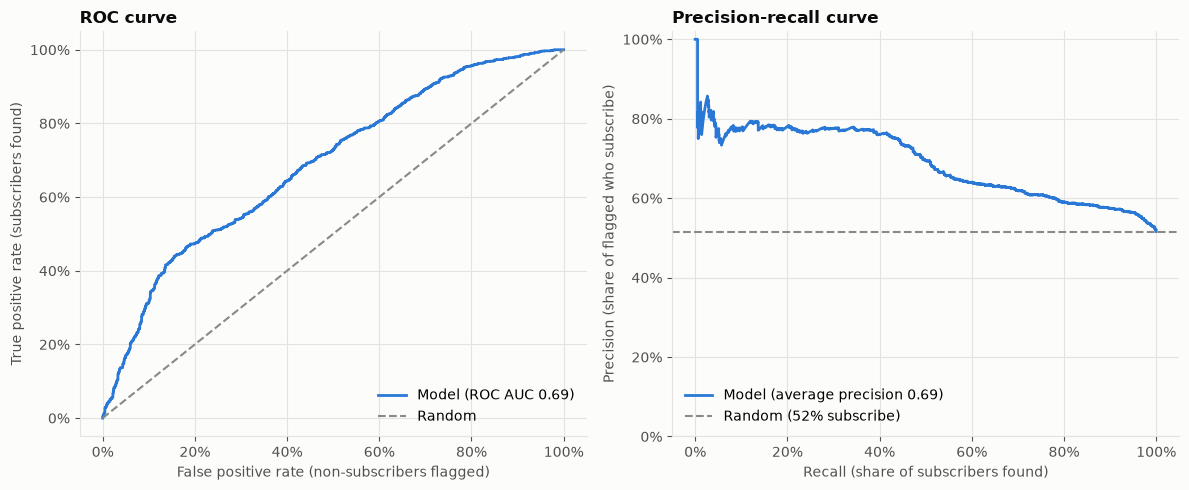

In [24]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
fpr, tpr, _ = roc_curve(y_test, scores_test)
ax1.plot(fpr, tpr, color=BLUE, label=f'Model (ROC AUC {roc_auc_score(y_test, scores_test):.2f})')
ax1.plot([0, 1], [0, 1], color=GRAY, linestyle='--', linewidth=1.5, label='Random')
ax1.set_xlabel('False positive rate (non-subscribers flagged)')
ax1.set_ylabel('True positive rate (subscribers found)')
ax1.set_title('ROC curve')
ax1.legend(loc='lower right')
precision, recall, _ = precision_recall_curve(y_test, scores_test)
ax2.plot(recall, precision, color=BLUE, label=f'Model (average precision {average_precision_score(y_test, scores_test):.2f})')
ax2.axhline(y_test.mean(), color=GRAY, linestyle='--', linewidth=1.5, label=f'Random ({pct(y_test.mean(), 0)} subscribe)')
ax2.set_xlabel('Recall (share of subscribers found)')
ax2.set_ylabel('Precision (share of flagged who subscribe)')
ax2.set_title('Precision-recall curve')
ax2.set_ylim(0, 1.02)
ax2.legend(loc='lower left')
for ax in (ax1, ax2):
    ax.xaxis.set_major_formatter(percent_axis)
    ax.yaxis.set_major_formatter(percent_axis)
plt.tight_layout()
plt.show()

- The model ranks the 2010 clients with a **ROC AUC of 0.69**, clearly above random and practically tied with gradient boosting.
- Its **average precision of 0.69** compares with 0.52 for a random ranking, the 2010 subscription rate.
- The test result is better than the validation result (0.60). The final model also learned from the second half of 2009, which is much closer to 2010 than the mass period was to the validation months.

### 7.2 Cumulative gains: share of subscribers reached by share of clients called

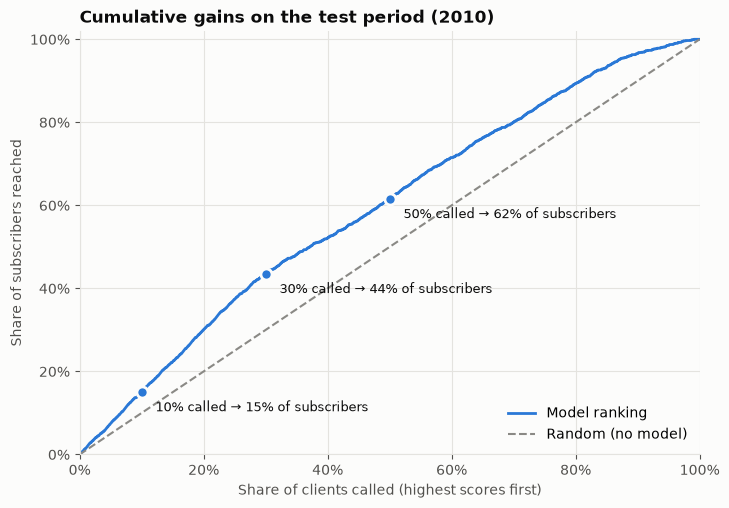

In [25]:
order = np.argsort(-scores_test)
y_sorted = y_test.to_numpy()[order]
share_called = np.arange(1, len(y_sorted) + 1) / len(y_sorted)
share_subscribers = np.cumsum(y_sorted) / y_sorted.sum()

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(share_called, share_subscribers, color=BLUE, label='Model ranking')
ax.plot([0, 1], [0, 1], color=GRAY, linestyle='--', linewidth=1.5, label='Random (no model)')
for share in (0.1, 0.3, 0.5):
    reached = share_subscribers[int(share * len(share_subscribers)) - 1]
    ax.plot(share, reached, 'o', markersize=8, color=BLUE, markeredgecolor=SURFACE, markeredgewidth=2)
    ax.annotate(f'{pct(share, 0)} called → {pct(reached, 0)} of subscribers', (share, reached),
                xytext=(10, -14), textcoords='offset points', fontsize=9, color=INK)
ax.set_xlabel('Share of clients called (highest scores first)')
ax.set_ylabel('Share of subscribers reached')
ax.xaxis.set_major_formatter(percent_axis)
ax.yaxis.set_major_formatter(percent_axis)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_title('Cumulative gains on the test period (2010)')
ax.legend(loc='lower right')
plt.show()

In [26]:
budget = []
for share in (0.1, 0.2, 0.3, 0.5, 0.7, 1.0):
    n = int(share * len(y_sorted))
    budget.append({'clients called': pct(share, 0), 'calls': f'{n:,}',
                   'subscribers reached': pct(y_sorted[:n].sum() / y_sorted.sum()),
                   'subscription rate among called': pct(y_sorted[:n].mean()),
                   'lift': f'{y_sorted[:n].mean() / y_test.mean():.2f}x'})
pd.DataFrame(budget).set_index('clients called')

,calls,subscribers reached,subscription rate among called,lift
clients called,,,,
10%,262,15.1%,77.9%,1.51x
20%,524,30.0%,77.5%,1.50x
30%,786,43.6%,74.9%,1.45x
50%,"1,310",61.6%,63.6%,1.23x
70%,"1,833",80.0%,59.0%,1.14x
100%,"2,620",100.0%,51.6%,1.00x


- Calling the **top 30% reaches 44% of the subscribers**, and 75% of the clients called subscribe, against 52% when calling at random.
- The lift is about **1.5x for the top 20%**. It cannot be much higher in 2010: when half the clients subscribe, the best possible lift is 1.9x.
- The gain is concentrated at the top of the ranking. Section 7.3 shows where the model separates clients well and where it does not.

### 7.3 Scores and observed rates

In [27]:
deciles = pd.DataFrame({'subscribed': y_test.to_numpy(), 'score': scores_test})
deciles['decile'] = 10 - pd.qcut(deciles['score'].rank(method='first'), 10, labels=False)
by_decile = deciles.groupby('decile').agg(clients=('subscribed', 'size'), subscription_rate=('subscribed', 'mean'),
                                          mean_score=('score', 'mean'))
by_decile.index.name = 'decile (1 = highest scores)'
print(f'Training period subscription rate: {pct(y[is_history].mean())}, test period: {pct(y_test.mean())}')
by_decile.style.format({'subscription_rate': '{:.1%}', 'mean_score': '{:.3f}'})

Training period subscription rate: 9.2%, test period: 51.6%


,clients,subscription_rate,mean_score
decile (1 = highest scores),,,
1,262,77.9%,0.529
2,262,77.1%,0.436
3,262,69.8%,0.321
4,262,44.3%,0.236
5,262,48.9%,0.200
6,262,51.1%,0.174
7,262,43.9%,0.151
8,262,48.1%,0.126
9,262,37.4%,0.097


- **The top three deciles** subscribe at 70% to 78%, and **the bottom decile** at 18%.
- **Deciles 4 to 8** all subscribe at 44% to 51%, close to the average: the model does not tell these clients apart. Its value is in finding the best fifth to third of the list, and the clients not worth calling.
- **The scores are not probabilities for 2010.** The model learned from periods where 9% subscribed, so its scores average about 0.23, while 52% of the 2010 clients subscribed. The ranking still holds, because a change in the overall rate moves all the scores together. But the scores must be **recalibrated** on recent months before being read as probabilities (section 9).

### 7.4 Classification metrics at an operating point

For a concrete reference, take the policy of **calling the top 30% of clients**. Treating "called" as the positive prediction:

In [28]:
cutoff = np.quantile(scores_test, 0.7)
y_pred = (scores_test >= cutoff).astype(int)

print(f'Precision: {precision_score(y_test, y_pred):.3f}  (base rate {y_test.mean():.3f})')
print(f'Recall:    {recall_score(y_test, y_pred):.3f}  (random: 0.300)')
print(f'F1 score:  {f1_score(y_test, y_pred):.3f}')

pd.DataFrame(confusion_matrix(y_test, y_pred),
             index=['actual: did not subscribe', 'actual: subscribed'],
             columns=['not called', 'called']).style.format('{:,}')

Precision: 0.749  (base rate 0.516)
Recall:    0.436  (random: 0.300)
F1 score:  0.551


,not called,called
actual: did not subscribe,"1,071",197
actual: subscribed,763,589


Three in four clients called subscribe (precision 0.75, against 0.52 at random), and the calls reach 44% of all subscribers (recall 0.44, against 0.30 at random). The right share to call depends on the cost of a call and the value of a deposit, which the data does not give; the table in section 7.2 shows what each budget buys.

### 7.5 What a random split would have reported

In [29]:
WITH_CALENDAR = FEATURES + CALENDAR_CATEGORICAL + CALENDAR_NUMERIC
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X[WITH_CALENDAR], y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

random_split = {}
for features, label in [(WITH_CALENDAR, 'with month and day'), (FEATURES, 'without month and day')]:
    pipeline = make_pipeline(HistGradientBoostingClassifier(random_state=RANDOM_STATE),
                             [c for c in features if c in CATEGORICAL + CALENDAR_CATEGORICAL],
                             [c for c in features if c in NUMERIC + CALENDAR_NUMERIC])
    pipeline.fit(X_train_r[features], y_train_r)
    random_split[f'Random split, gradient boosting {label}'] = roc_auc_score(
        y_test_r, pipeline.predict_proba(X_test_r[features])[:, 1])
random_split['Split by time (this notebook), test 2010'] = roc_auc_score(y_test, scores_test)
pd.Series(random_split, name='ROC AUC on the held-out data').round(3).to_frame()

,ROC AUC on the held-out data
"Random split, gradient boosting with month and day",0.804
"Random split, gradient boosting without month and day",0.765
"Split by time (this notebook), test 2010",0.689


The same data, split at random 80/20 instead of by time:

- With `month` and `day`, gradient boosting reaches a **ROC AUC of 0.80**.
- Without them, 0.77.
- Split by time, the model in this notebook reaches 0.69.

A random split puts calls from every period in both train and test. The model can then recognize the period of a call, from its month and day but also from the phone type and the history columns, and use that period's subscription rate. This works on a test set drawn from the same months, but not on future calls, which come from a period the model has not seen. **0.69 is the realistic estimate.**

## 8. What drives subscription

**Permutation importance** measures how much the test ROC AUC drops when one feature's values are shuffled. Original columns are shuffled before encoding, so each categorical feature counts as one feature. The logistic regression's **odds ratios** then show the direction of each effect.

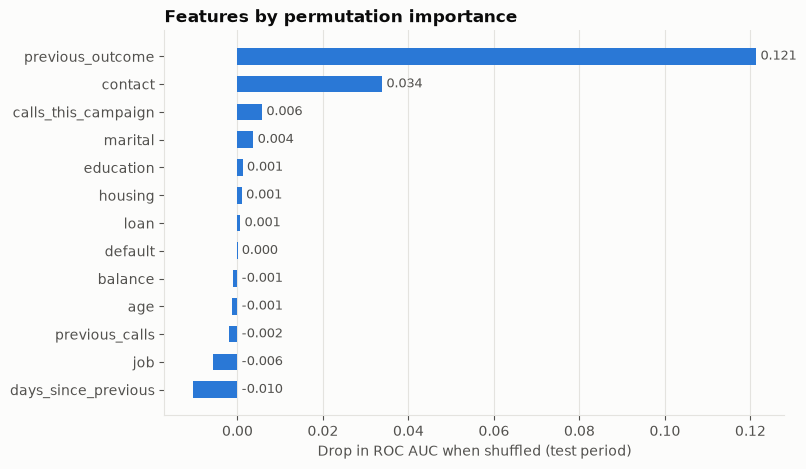

In [30]:
importance = permutation_importance(loaded_model, X.loc[is_test, FEATURES], y_test, scoring='roc_auc',
                                    n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.Series(importance.importances_mean, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importance.index, importance.values, color=BLUE, height=0.6)
for y_pos, value in enumerate(importance.values):
    ax.text(max(value, 0) + 0.001, y_pos, f'{value:.3f}', va='center', fontsize=9, color=INK_2)
ax.set_xlabel('Drop in ROC AUC when shuffled (test period)')
ax.set_title('Features by permutation importance')
ax.grid(axis='y', visible=False)
plt.show()

In [31]:
names = loaded_model.named_steps['preprocess'].get_feature_names_out()
coefficients = pd.Series(loaded_model.named_steps['model'].coef_[0], index=names)
coefficients.index = coefficients.index.str.replace('categorical__', '').str.replace('numeric__', '')
odds = np.exp(coefficients).rename('odds ratio').to_frame()
odds['effect'] = np.where(odds['odds ratio'] > 1, 'raises', 'lowers')
pd.concat([odds.sort_values('odds ratio', ascending=False).head(8),
           odds.sort_values('odds ratio').head(8)]).style.format({'odds ratio': '{:.2f}'})

,odds ratio,effect
previous_outcome_success,2.47,raises
job_retired,1.46,raises
contact_cellular,1.41,raises
job_student,1.27,raises
days_since_previous_under 3 months,1.25,raises
balance,1.22,raises
days_since_previous_over 12 months,1.17,raises
days_since_previous_3-6 months,1.16,raises
contact_unknown,0.61,lowers
previous_outcome_failure,0.63,lowers


- **The outcome of the previous campaign** dominates. Shuffling it costs 0.12 of ROC AUC, against 0.03 for the phone type and less than 0.01 for every other feature. A previous success multiplies the odds of subscribing by about 2.5.
- **The phone type** comes second: a mobile phone raises the odds, an unknown phone type lowers them.
- **Repeated calls in the same campaign, housing loans and personal loans** lower the odds. A higher balance raises them, and so does being retired or a student.
- **Job and days since the previous campaign have slightly negative importance in 2010.** Their effects, learned mostly from 2008–2009, did not hold in the test period. The client's history with the bank matters more than their profile.

Every category has its own column, so each odds ratio compares a category with the average of its group. For numeric features, it is the effect of one standard deviation.

## 9. Using the model in production

**How it runs.** Telemarketing works in campaign waves, so the model fits a **batch** process:

1. Before each wave, build the features of every candidate client from the bank's records (profile, loans, balance, phone type and history of earlier campaigns) with `build_features`.
2. Score them with the saved pipeline and sort the list.
3. Call from the top, as far as the team's capacity allows (section 7.2).

`build_features` and the pipeline should live in one small package, used both for training and for scoring. Features are then computed the same way in both places, avoiding *training–serving skew* (for example, `pdays` counted differently by the scoring system).

**Recalibration.** The scores rank well but are not probabilities for a new period (section 7.3). Recalibrating on the results of the latest month turns them back into usable probabilities, for example to compare the expected value of a call with its cost.

**Monitoring and retraining:**

- Each month, track the subscription rate by score decile and the ROC AUC as call results come in.
- Watch the mix of clients scored: the share called before, the phone types and the score distribution. Section 2.3 shows how fast the mix can change.
- Retrain after each campaign wave, or at least monthly, on all the history so far. Validate on the latest period before replacing the model in use.

**Limits:**

- The data only covers clients the bank **chose** to call. The model ranks clients similar to those and says little about others.
- It predicts who subscribes **when called**, not who subscribes **because** they were called. Some high-score clients might subscribe anyway; only an experiment can measure the effect of the call.
- The data covers 2008–2010, years of financial crisis and of a clear change in how the bank ran its campaign. The model should be revalidated on recent data before use.
- The model uses age, job and marital status. Their use in targeting a financial product should be reviewed for fairness and regulatory compliance.

**Implementation.** The project's [`bank_marketing` package](src/bank_marketing) implements this process as a monthly batch job, with monitoring, recalibration and retraining, and replays it on 2010. See the [project README](README.md#factory-production-pipeline).

## 10. Actionable insights and next steps

**Actionable insights**

1. **Call previous subscribers first.** A success in an earlier campaign is by far the strongest signal, in every period.
2. **Do not assume that recontacting pays off by itself.** Clients whose earlier campaign failed subscribe less often than new clients.
3. **Limit repeated calls.** The subscription rate falls with each extra call in the same campaign, from 15% at the first call to 6% after six or more. A cap on attempts per client would free capacity for better prospects; the right cap depends on the cost of a call.
4. **Prefer mobile numbers and always record the phone type.** Mobile calls convert better, and the months without a recorded phone type were the weakest.
5. **Do not plan the calendar on this data.** The apparent best months (March, September, October and December) reflect when the selective campaign ran, not a seasonal effect.

**Next steps**

1. **Measure the effect of the call** with an experiment by score band (called against not called), to learn which clients subscribe *because* they are called.
2. **Add data the bank has but this dataset lacks**, such as products held, transaction history and time as a client. They are likely stronger signals than the profile columns.
3. **Recalibrate and retrain** after each campaign wave, monitoring the subscription rate by score decile.
4. **Revisit the feature selection with a rolling validation** over several periods: job and days since the previous campaign did not help in 2010.